# Project 1: Experiments (Task 5, and Task 6 if done)

This notebook is a skeleton. Keep its sections and fill them in.

- All agents are defined in `agents.py`. Import them from there; do not define agents in this notebook.
- Run every season with `play(agent, bay)` from `agents.py`.
- Document each step: what you run, why, and what you observe.
- The notebook must run from top to bottom without errors (Kernel, Restart and Run All).

In [29]:
import sys
import importlib
# Create a mock 'imp' module to support legacy packages and extensions in Python 3.13+
try:
    import imp
except ImportError:
    from types import ModuleType
    imp = ModuleType('imp')
    imp.reload = importlib.reload
    sys.modules['imp'] = imp

%reload_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import urllib.request
url = "https://raw.githubusercontent.com/VeronikaSyncakova/ImProc_img/main/Malis_P1/fishing.py"
urllib.request.urlretrieve(url, "fishing.py")
url = "https://raw.githubusercontent.com/VeronikaSyncakova/ImProc_img/main/Malis_P1/agents.py"
urllib.request.urlretrieve(url, "agents.py")

from fishing import FishingBay, ContextualBay, load_log, choices
from agents import play, RandomAgent, RandomContextualAgent  # add your own agents here

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

## 0. Your team logs

Put the JSON log of each team member next to this notebook and list the files below.

In [30]:
url = "https://raw.githubusercontent.com/VeronikaSyncakova/ImProc_img/main/Malis_P1/fishing_log_soleiman.json"
urllib.request.urlretrieve(url, "fishing_log_soleiman.json")
url = "https://raw.githubusercontent.com/VeronikaSyncakova/ImProc_img/main/Malis_P1/fishing_log_syncakov.json"
urllib.request.urlretrieve(url, "fishing_log_syncakov.json")
url = "https://raw.githubusercontent.com/VeronikaSyncakova/ImProc_img/main/Malis_P1/fishing_log_sytcheva.json"
urllib.request.urlretrieve(url, "fishing_log_sytcheva.json")

TEAM_LOG_FILES = [
    "fishing_log_soleiman.json",
    "fishing_log_syncakov.json",
    "fishing_log_sytcheva.json",
]
logs = [load_log(path) for path in TEAM_LOG_FILES]
# The spots chosen and the catches of all members in all seasons
for member in range(3):
  print("\n***",logs[member]['student_id'], "***")
  for season in range(1,3+1):
    spots, catches = choices(logs[member], season)
    print("SEASON ", season)
    print(" Spots: ", spots)
    print(" Catches: ", catches)


Season:  1 
Total:  138.6 Best possible:  153.0 

Season:  2 
Total:  46.8 Best possible:  80.0 

Season:  3 
Total:  214.9 Best possible:  264.0 

Season:  1 
Total:  138.6 Best possible:  153.0 

Season:  2 
Total:  46.8 Best possible:  80.0 

Season:  3 
Total:  214.9 Best possible:  264.0 

Season:  1 
Total:  138.6 Best possible:  153.0 

Season:  2 
Total:  46.8 Best possible:  80.0 

Season:  3 
Total:  214.9 Best possible:  264.0 


*** soleiman ***
SEASON  1
 Spots:  [3, 1, 0, 2, 4, 3, 1, 0, 2, 4, 0, 0, 3, 0, 4, 3, 0, 4, 1, 2, 0, 3, 4, 4, 0, 0, 0, 3, 4, 0]
 Catches:  [6.3, 0, 4.1, 1.6, 7.7, 11.3, 5.6, 13.6, 5.2, 10.5, 12.1, 3.6, 4.8, 8.2, 7.8, 7.5, 7.1, 7.9, 8.4, 4.4, 5, 7.7, 9.8, 7.1, 10.5, 4.4, 9.7, 4.8, 6.7, 9.2]
SEASON  2
 Spots:  [3, 0, 0, 0, 0, 0, 4, 1, 0, 3]
 Catches:  [8.6, 10.2, 13.1, 12.9, 10.7, 8, 4.7, 4.4, 4.7, 6.9]
SEASON  3
 Spots:  [3, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 4, 4, 0, 0, 1, 3, 3, 3, 3, 2, 0, 0, 0, 0, 3, 1, 3]
 Catches:  [3.6, 10.8, 9.1, 12, 7.8, 8.3,

## Example: one season played by the random agent

`FishingBay(season, seed)` creates a random bay. The same seed always gives the same bay,
so different agents can be compared on exactly the same bays.

In [ ]:
bay = FishingBay(season=1, seed=0)
agent = RandomAgent(seed=0)
total = play(agent, bay)
print(f"Total catch: {total} kg over {bay.days} days")
print("Spots chosen:", [spot for spot, catch in bay.history])

Total catch: 136.2 kg over 30 days
Spots chosen: [4, 3, 2, 1, 1, 0, 0, 0, 0, 4, 3, 4, 2, 3, 4, 3, 3, 2, 2, 4, 1, 4, 3, 0, 1, 4, 2, 0, 3, 3]


## 1. Random bays

Evaluate every agent on at least 1000 random bays for each season (1, 2 and 3), and report the distribution of the results.

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from agents import play, RandomAgent, HumanRuleAgent
from fishing import FishingBay

# Define the number of random bays to test
NUM_BAYS = 1000

# We will store the results of our experiments here
eval_results = []


def calculate_dq(bay):
# How good the agent's decisions were, independent of pure luck
# 100 => the best score
# < 50 => sub-optimal spots
    info = bay.reveal()
    expected = 0
    for day, (spot, catch) in enumerate(bay.history, start=1):
        # The true expected value of the fish at that spot on that day
        means = info["means"]

        # station's conditions change -> switch the means
        if "change_day" in info and day >= info["change_day"]:
            means = info["means_after_change"]
        # Sum of true expected value
        expected += means[spot]
    # Result if everytime chosen best spot
    best = bay.best_possible()
    return 100 * expected / best


"""
for season in [1, 2, 3]:
    # Evaluate the RandomAgent as a baseline
    random_agent_catches = []
    dq = []
    for seed in range(NUM_BAYS):
        bay = FishingBay(season=season, seed=seed)
        agent = RandomAgent(seed=seed)
        total_catch = play(agent, bay)
        random_agent_catches.append(total_catch)
        dq.append(calculate_dq(bay))

    # Save metrics
    eval_results.append({
        'Season': f'Season {season}',
        'Agent': 'RandomAgent',
        "Catch" : round(np.mean(random_agent_catches), 2),
        "Expected Catch": round(bay.best_possible()*np.mean(dq)/100, 2), # No luck
        "DQ": round(np.mean(dq), 2)
    })

for season in [1, 2, 3]:
    # Evaluate the HumanRuleAgent
    human_rule_agent_catches = []
    dq = []
    for seed in range(NUM_BAYS):
        bay = FishingBay(season=season, seed=seed)
        agent = HumanRuleAgent(seed=seed)
        total_catch = play(agent, bay)
        human_rule_agent_catches.append(total_catch)
        dq.append(calculate_dq(bay))

    # Save metrics
    eval_results.append({
        'Season': f'Season {season}',
        'Agent': 'HumanRuleAgent',
        "Catch" : round(np.mean(human_rule_agent_catches), 2),
        "Expected Catch": round(bay.best_possible()*np.mean(dq)/100, 2), # No luck
        "DQ": round(np.mean(dq), 2)
    })

for season in [1, 2, 3]:
# Evaluate the UCBAgent
  ucb_agent_catches = []
  dq = []
  for seed in range(NUM_BAYS):
      bay = FishingBay(season=season, seed=seed)
      agent = UCBAgent(seed=seed)
      total_catch = play(agent, bay)
      ucb_agent_catches.append(total_catch)
      dq.append(calculate_dq(bay))

  # Save metrics
  eval_results.append({
          'Season': f'Season {season}',
          'Agent': 'UCBAgent',
          "Catch" : round(np.mean(ucb_agent_catches), 2),
          "Expected Catch": round(bay.best_possible()*np.mean(dq)/100, 2), # No luck
          "DQ": round(np.mean(dq), 2)
      })
for season in [1, 2, 3]:
# Evaluate the EpsilonGreedyAgent
  ep_greedy_agent_catches = []
  dq = []
  for seed in range(NUM_BAYS):
      bay = FishingBay(season=season, seed=seed)
      agent = EpsilonGreedyAgent(seed=seed)
      total_catch = play(agent, bay)
      ep_greedy_agent_catches.append(total_catch)
      dq.append(calculate_dq(bay))

  # Save metrics
  eval_results.append({
          'Season': f'Season {season}',
          'Agent': 'EpsilonGreedyAgent',
          "Catch" : round(np.mean(ep_greedy_agent_catches), 2),
          "Expected Catch": round(bay.best_possible()*np.mean(dq)/100, 2), # No luck
          "DQ": round(np.mean(dq), 2)
      })
"""
eval_results = []
agents_to_test = {
    'RandomAgent': RandomAgent,
    'HumanRuleAgent': HumanRuleAgent,
    'UCBAgent': UCBAgent,
    'EpsilonGreedyAgent': EpsilonGreedyAgent
}

for season in [1, 2, 3]:
    # Dictionary to hold metrics temporarily for this season
    season_data = {name: {'catches': [], 'dq': [], 'best_possible': []} for name in agents_to_test}

    for seed in range(NUM_BAYS):
        for agent_name, agent_class in agents_to_test.items():
            # Create a clean, identical bay for this agent using the same seed
            bay = FishingBay(season=season, seed=seed)
            agent = agent_class(seed=seed)

            total_catch = play(agent, bay)
            dq_val = calculate_dq(bay)

            season_data[agent_name]['catches'].append(total_catch)
            season_data[agent_name]['dq'].append(dq_val)
            season_data[agent_name]['best_possible'].append(bay.best_possible())

    # Aggregate and save metrics for each agent in this season
    for agent_name in agents_to_test:
        mean_catch = np.mean(season_data[agent_name]['catches'])
        mean_dq = np.mean(season_data[agent_name]['dq'])
        mean_best = np.mean(season_data[agent_name]['best_possible'])

        eval_results.append({
            'Season': f'Season {season}',
            'Agent': agent_name,
            "Catch": round(mean_catch, 2),
            "Expected Catch": round(mean_best * mean_dq / 100, 2),
            "DQ": round(mean_dq, 2)
        })

df_eval = pd.DataFrame(eval_results)
display(df_eval)

,Season,Agent,Catch,Expected Catch,DQ
0,Season 1,RandomAgent,181.25,180.54,69.44
1,Season 1,HumanRuleAgent,195.53,194.54,74.83
2,Season 1,UCBAgent,234.87,234.68,90.27
3,Season 1,EpsilonGreedyAgent,202.58,202.26,77.80
4,Season 2,RandomAgent,61.24,60.57,69.57
5,Season 2,HumanRuleAgent,65.74,64.88,74.52
6,Season 2,UCBAgent,70.05,69.87,80.25
7,Season 2,EpsilonGreedyAgent,63.65,63.38,72.80
8,Season 3,RandomAgent,182.73,181.88,69.96
9,Season 3,HumanRuleAgent,195.35,194.23,74.71


## 2. Your team's bays

Run your agents on the bays played by your team members and compare with their results.
`FishingBay.from_log(log, season)` rebuilds the exact bay a member played, with the same catch on every day.

In [31]:
# Example: rebuild the Season 1 bay of the first member
# bay = FishingBay.from_log(logs[0], season=1)

# Your code here

# calculate decision quality for each season and each member

def calculate_dq(bay):
    info = bay.reveal()
    expected = 0

    for day, (spot, catch) in enumerate(bay.history, start=1):
        means = info["means"]

        if "change_day" in info and day >= info["change_day"]:
            means = info["means_after_change"]

        expected += means[spot]

    best = bay.best_possible()
    return 100 * expected / best


results = []

for name in TEAM_LOG_FILES:
    log = load_log(name)
    # Extract 'xxx' from 'json/fishing_log_xxx.json'
    member_name = name.split("_")[-1].replace(".json", "")

    for season in [1, 2, 3]:
    # for season in [1]:
        bay = FishingBay.from_log(log, season)
        spots, catches = choices(log, season)

        for spot in spots:
            bay.fish(spot)

        dq = calculate_dq(bay)

        results.append({
            "Member": member_name,
            "Season": season,
            "Catch" : bay.total,
            "Expected Catch": bay.best_possible()*dq/100,
            "DQ": round(dq, 2)
        })

df = pd.DataFrame(results)

display(df)

,Member,Season,Catch,Expected Catch,DQ
0,soleiman,1,212.6,227.9,78.32
1,soleiman,2,84.2,82.9,92.11
2,soleiman,3,226.0,212.5,74.17
3,syncakov,1,260.1,262.8,88.48
4,syncakov,2,77.5,81.8,82.63
5,syncakov,3,170.6,163.7,62.36
6,sytcheva,1,175.0,202.5,68.18
7,sytcheva,2,85.5,86.5,96.11
8,sytcheva,3,196.4,185.6,67.99


In [33]:
# Running HumanRule, UCB and EpsilonGreedy agents on the bays played by us(members)
# "Then compare your agents with your team members on the bays they played, to see whether and where they do better."
from agents import play, HumanRuleAgent, UCBAgent, EpsilonGreedyAgent

# using calculate_dq(bay) that was already defined

results = []
TEAM_LOG_FILES = ["fishing_log_soleiman.json", "fishing_log_syncakov.json", "fishing_log_sytcheva.json"]

for name in TEAM_LOG_FILES:
    log = load_log(name)
    member_name = log.get("student_id", name.split("_")[-1].replace(".json", ""))

    for season in [1, 2, 3]:
        # Get the member's actual total catch from their log for comparison
        member_choices, member_catches = choices(log, season)
        member_total_catch = sum(member_catches)
        # Rebuild the exact bay the member played using their bay_seed
        bay_for_member = FishingBay.from_log(log, season)

        # Calculate the member's own DQ by replaying their choices on the bay
        for spot in member_choices:
            bay_for_member.fish(spot)
        member_dq = calculate_dq(bay_for_member)

        # Run HumanRule agent on the same bay as the member had
        human_bay = FishingBay.from_log(log, season)
        human_agent = HumanRuleAgent(seed=0)
        human_agent_total_catch = play(human_agent, human_bay)
        human_agent_dq = calculate_dq(human_bay)

        # Run UCB agent on the same bay as the member had
        ucb_bay = FishingBay.from_log(log, season)
        ucb_agent = UCBAgent(seed=0)
        ucb_agent_total_catch = play(ucb_agent, ucb_bay)
        ucb_agent_dq = calculate_dq(ucb_bay)

        # Run EpsilonGreedy agent on the same bay as the member had
        ep_greedy_bay = FishingBay.from_log(log, season)
        ep_greedy_agent = EpsilonGreedyAgent(seed=0)
        ep_greedy_agent_total_catch = play(ep_greedy_agent, ep_greedy_bay)
        ep_greedy_agent_dq = calculate_dq(ep_greedy_bay)

        # Save results to compare
        results.append({
            "Member": member_name,
            "Season": season,
            "Member Catch": member_total_catch,
            "Member DQ": round(member_dq, 2),
            "HumanAgent Catch": human_agent_total_catch,
            "HumanAgent DQ": round(human_agent_dq, 2),
            "UCBAgent Catch": ucb_agent_total_catch,
            "UCBAgent DQ": round(ucb_agent_dq, 2),
            "EpsilonGreedyAgent Catch": ep_greedy_agent_total_catch,
            "EpsilonGreedyAgent DQ": round(ep_greedy_agent_dq, 2)
        })

df_comparison = pd.DataFrame(results)
display(df_comparison)

,Member,Season,Member Catch,Member DQ,HumanAgent Catch,HumanAgent DQ,UCBAgent Catch,UCBAgent DQ,EpsilonGreedyAgent Catch,EpsilonGreedyAgent DQ
0,soleiman,1,212.6,78.32,198.6,71.89,256.1,95.02,238.7,90.14
1,soleiman,2,84.2,92.11,90.2,92.44,84.7,87.56,81.2,88.56
2,soleiman,3,226.0,74.17,246.8,77.45,200.8,75.95,228.8,77.03
3,syncakov,1,260.1,88.48,250.8,81.31,283.2,92.02,254.6,89.39
4,syncakov,2,77.5,82.63,76.5,73.03,80.7,78.69,88.7,84.04
5,syncakov,3,170.6,62.36,175.5,63.66,221.4,79.09,173.6,60.08
6,sytcheva,1,175.0,68.18,187.2,69.39,287.3,91.31,263.2,83.91
7,sytcheva,2,85.5,96.11,82.9,86.67,80.0,88.78,82.9,90.00
8,sytcheva,3,196.4,67.99,195.3,73.92,236.7,92.16,234.3,86.04


## 3. Seasons 2 and 3

Identify the best agent for Season 2 and for Season 3, and explain why.
`FishingBay(season, seed, days=..., shift_day=...)` lets you experiment with longer seasons.

In [41]:
# Your code here
NUM_TESTS = 100
standard_scores = []
extended_scores = []

for seed in range(NUM_TESTS):
    # Standard Season (30 days, shift at day 16)
    bay_standard = FishingBay(season=3, seed=seed)
    agent_standard = UCBAgent(seed=seed)
    play(agent_standard, bay_standard)

    # Get details about the environmental shift
    info_standard = bay_standard.reveal()
    shift_day_std = info_standard.get("change_day", 16)
    new_means_std = info_standard["means_after_change"]

    # Find the best possible spot and its value after the shift
    best_spot_std = np.argmax(new_means_std)
    best_value_std = new_means_std[best_spot_std]

    total_earned_std = 0
    total_possible_std = 0

    # Look at every day in the history after the shift happened
    for day_number, (chosen_spot, catch_amount) in enumerate(bay_standard.history, start=1):
        if day_number >= shift_day_std:
            total_earned_std += new_means_std[chosen_spot]
            total_possible_std += best_value_std

    # Calculate Decision Quality (DQ) percentage for the post-shift period
    if total_possible_std > 0:
        dq_std = (total_earned_std / total_possible_std) * 100
    else:
        dq_std = 0

    standard_scores.append(dq_std)

    # Extended Season (200 days, shift at day 100)
    bay_extended = FishingBay(season=3, seed=seed, days=200, shift_day=100)
    agent_extended = UCBAgent(seed=seed)
    play(agent_extended, bay_extended)

    info_extended = bay_extended.reveal()
    shift_day_ext = info_extended.get("change_day", 100)
    new_means_ext = info_extended["means_after_change"]

    best_spot_ext = np.argmax(new_means_ext)
    best_value_ext = new_means_ext[best_spot_ext]

    total_earned_ext = 0
    total_possible_ext = 0

    for day_number, (chosen_spot, catch_amount) in enumerate(bay_extended.history, start=1):
        if day_number >= shift_day_ext:
            total_earned_ext += new_means_ext[chosen_spot]
            total_possible_ext += best_value_ext

    if total_possible_ext > 0:
        dq_ext = (total_earned_ext / total_possible_ext) * 100
    else:
        dq_ext = 0

    extended_scores.append(dq_ext)

# Show the Final Comparison Table
comparison_table = pd.DataFrame({
    "Environment Setup": ["Standard (30 days, Shift 16)", "Extended (200 days, Shift 100)"],
    "Mean Post-Shift DQ (%)": [round(np.mean(standard_scores), 2), round(np.mean(extended_scores), 2)]
})

display(comparison_table)

,Environment Setup,Mean Post-Shift DQ (%)
0,"Standard (30 days, Shift 16)",80.54
1,"Extended (200 days, Shift 100)",84.72


## 4. One parameter

Study the effect of one parameter of one method.

,Season,Parameter Value,Mean DQ
0,Season 1,0.1,90.77
1,Season 1,0.5,90.74
2,Season 1,1.0,90.63
3,Season 1,2.0,90.00
4,Season 1,5.0,85.21
5,Season 1,10.0,78.89
6,Season 2,0.1,80.97
7,Season 2,0.5,80.90
8,Season 2,1.0,80.70
9,Season 2,2.0,80.38


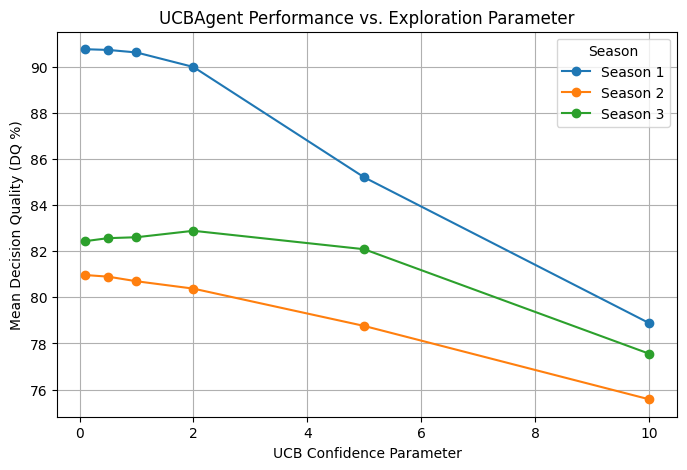

In [39]:
# Your code here
# Define a range of values for the UCB exploration parameter (The original agent was using c=2)
param_values = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
seasons = [1, 2, 3]
NUM_BAYS = 300  # Number of random bays per parameter setting

# Accumulate the data here
sweep_results = []

for season in seasons:
    for val in param_values:
        dq_list = []

        for seed in range(NUM_BAYS):
            bay = FishingBay(season=season, seed=seed)
            # UCBAgent with the specific parameter value
            agent = UCBAgent(seed=seed, c=val)

            play(agent, bay)
            dq_list.append(calculate_dq(bay))
        # Collect data
        sweep_results.append({
            'Season': f'Season {season}',
            'Parameter Value': val,
            'Mean DQ': round(np.mean(dq_list), 2)
        })

df_sweep = pd.DataFrame(sweep_results)
display(df_sweep)

# Plotting the results
pivot_df = df_sweep.pivot(index='Parameter Value', columns='Season', values='Mean DQ')

pivot_df.plot(kind='line', marker='o', figsize=(8, 5))
plt.title('UCBAgent Performance vs. Exploration Parameter')
plt.xlabel('UCB Confidence Parameter')
plt.ylabel('Mean Decision Quality (DQ %)')
plt.grid(True)
plt.legend(title='Season')
plt.show()

## 5. Part IV (optional): contextual bay

`ContextualBay(seed)` lasts 300 days. Each morning, your agent receives the conditions
`x = [wind_kmh, waves_m, tide_m]` before choosing a spot. Contextual agents are subclasses of
`ContextualAgent` in `agents.py`.

In [ ]:
bay = ContextualBay(seed=0)
total = play(RandomContextualAgent(seed=0), bay)
print(f"Random contextual agent: {total} kg over {bay.days} days")

# Your code here